In [20]:
from safari_tools import SaFariAnnotation
from safari_sampler import SaFariSampler
# from safari_downloader import SaFariDownloader
from safari_vww import SaFariVWW
from pathlib import Path
import pandas as pd
# import json

In [1]:
from safari_tools import SaFariAnnotation
for s in ("train", "test"):
    ann = SaFariAnnotation.from_json(f"../data/hf_sa_fari/annotation/sa_fari_{s}.json")
    empty = [v for v in ann.video_names() if sum(ann.animal_presence_frame_label(v)) == 0]
    print(s, "videos with no annotated frame:", len(empty), empty[:10])
print("setup videos:", {v: int(sum(SaFariAnnotation.from_json('../data/hf_sa_fari/annotation/sa_fari_train.json')
                                     .animal_presence_frame_label(v))) for v in ("sa_fari_005269", "sa_fari_006464")})

train videos with no annotated frame: 2 ['sa_fari_005269', 'sa_fari_006464']
test videos with no annotated frame: 0 []
setup videos: {'sa_fari_005269': 0, 'sa_fari_006464': 0}


In [21]:
for s in ("train", "test"):
    ann = SaFariAnnotation.from_json(f"../data/hf_sa_fari/annotation/sa_fari_{s}.json")
    names = ann.video_names()
    frames = sum(len(ann.video_info(v)["file_names"]) for v in names)
    labels = [ann.animal_presence_frame_label(v) for v in names]
    labeled = sum(len(l) for l in labels)
    present = sum(int(sum(l)) for l in labels)
    _, _, meta = SaFariSampler(ann, pct=0.10, seed=0).build()
    print(f"{s}: {len(ann):,} videos, {frames:,} frames "
          f"({present:,} animal-present, {labeled - present:,} empty; labeled frames {labeled:,}) | "
          f"sampled {meta['total_selected']:,} "
          f"({meta['present']:,} animal-present, {meta['empty']:,} empty)")

train: 10,776 videos, 913,852 frames (665,446 animal-present, 248,406 empty; labeled frames 913,852) | sampled 98,506 (71,157 animal-present, 27,349 empty)
test: 833 videos, 72,477 frames (48,193 animal-present, 24,284 empty; labeled frames 72,477) | sampled 7,861 (5,201 animal-present, 2,660 empty)


In [ ]:
from safari_vww import _read_manifest, _valid_loc

ann   = SaFariAnnotation.from_json("../data/hf_sa_fari/annotation/sa_fari_train.json")
ann_t = SaFariAnnotation.from_json("../data/hf_sa_fari/annotation/sa_fari_test.json")

def loc(a, v):
    x = a.video_info(v).get("location_id")
    return str(x) if _valid_loc(x) else None

def summary(a, rows, name):
    vids = {p.split("/")[0] for p, _ in rows}
    locs = {loc(a, v) for v in vids} - {None}
    nloc = sum(loc(a, v) is None for v in vids)
    animal = sum(int(l) == 1 for _, l in rows)
    print(f"{name}: {len(rows):,} frames ({animal:,} animal, {len(rows) - animal:,} empty) | "
          f"{len(vids):,} videos | {len(locs):,} locations + {nloc:,} videos without location "
          f"= {len(locs) + nloc:,} groups")
    return vids, locs

tr_v, tr_l = summary(ann,   _read_manifest("../data/plans/split_train.csv"),     "train")
va_v, va_l = summary(ann,   _read_manifest("../data/plans/split_val.csv"),       "val")
test_rows  = _read_manifest("../data/plans/manifest_vww_test.csv")
te_v, te_l = summary(ann_t, test_rows,                                           "test")

rel_l = {loc(ann, v) for v in ann.video_names()} - {None}
for name, L in [("train release (all videos)", rel_l), ("final train", tr_l), ("final val", va_l)]:
    shared = sorted(te_l & L)
    n_frames = sum(loc(ann_t, p.split("/")[0]) in shared for p, _ in test_rows)
    print(f"test vs {name}: {len(L):,} locations | shared {len(shared):,} locations, {n_frames:,} test frames"
          + (f" | IDs: {shared[:20]}" if shared else ""))

train: 58,082 frames (34,738 animal, 23,344 empty) | 8,258 videos | 503 locations + 49 videos without location = 552 groups
val: 10,488 frames (6,497 animal, 3,991 empty) | 1,368 videos | 102 locations + 18 videos without location = 120 groups
test: 5,061 frames (2,401 animal, 2,660 empty) | 748 videos | 89 locations + 2 videos without location = 91 groups
test vs train release (all videos): 650 locations | shared 0 locations, 0 test frames
test vs final train: 503 locations | shared 0 locations, 0 test frames
test vs final val: 102 locations | shared 0 locations, 0 test frames


In [23]:
PLANS = Path("../data/plans")
OUT   = Path("display/animal_size"); OUT.mkdir(parents=True, exist_ok=True)
vww   = SaFariVWW(SaFariAnnotation.from_json("../data/hf_sa_fari/annotation/sa_fari_train.json"))
vww_t = SaFariVWW(SaFariAnnotation.from_json("../data/hf_sa_fari/annotation/sa_fari_test.json"))
SETS  = {"train": (vww, "split_train.csv"), "val": (vww, "split_val.csv"), "test": (vww_t, "manifest_vww_test.csv")}

F = pd.DataFrame([(s, p, l, a) for s, (v, m) in SETS.items() for p, l, a in v._frame_fracs(PLANS / m)],
                 columns=["split", "path", "label", "area"])
F["size_group"] = pd.cut(F.area, [0.025, 0.05, 0.10, 0.20, 1.01],
                         labels=["2.5-5%", "5-10%", "10-20%", ">=20%"]).astype(str)
F.loc[F.label == 0, "size_group"] = "empty"
F.to_csv(OUT / "frames_area.csv", index=False)

A = F[F.label == 1]
T = pd.crosstab(A.split, A.size_group).loc[list(SETS), ["2.5-5%", "5-10%", "10-20%", ">=20%"]]
T["median_area"] = A.groupby("split").area.median().round(3)
T.to_csv(OUT / "size_groups_by_split.csv")
print(T)

size_group  2.5-5%  5-10%  10-20%  >=20%  median_area
split                                                
train        11047  10212    7378   6101        0.074
val           1431   1270    1199   2597        0.140
test           782    769     447    403        0.072


small (2.5-5%): sa_fari_000638/00063.jpg | area 4.37% | original 1280x720, box 247x163 px
large (>=20%): sa_fari_000300/00032.jpg | area 21.65% | original 1280x720, box 575x347 px


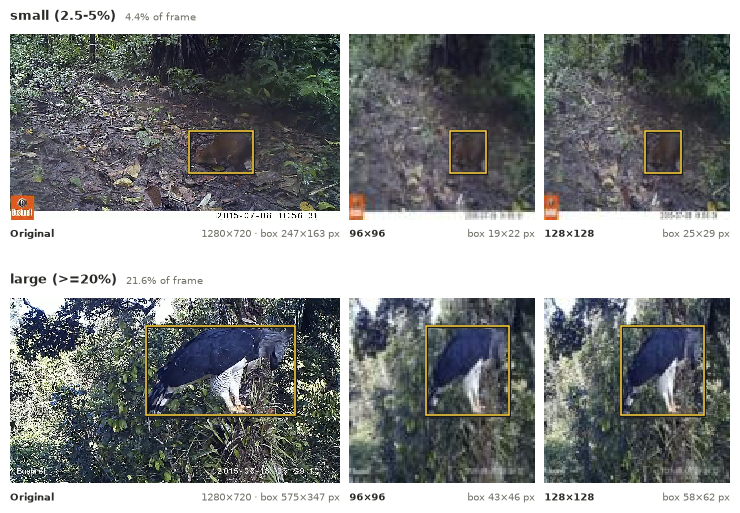

In [7]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.patches import Rectangle
from PIL import Image
from safari_tools import SaFariAnnotation

OUT = Path("display/resize"); OUT.mkdir(parents=True, exist_ok=True)

# ---------- style (same as the other figures) ----------
FONT = "Inter" if "Inter" in {f.name for f in font_manager.fontManager.ttflist} else "DejaVu Sans"
mpl.rcParams.update({"font.family": FONT, "font.size": 8, "pdf.fonttype": 42, "svg.fonttype": "none"})
INK, MUTED = "#2b2b28", "#6f6e66"
BOX, BOX_EDGE = "#ffd23f", "#1a1a1a"            # bright box with a dark outline: visible on any background
WIDTH = 7.2                                      # double-column width
UPS = 768                                        # small images are enlarged with nearest-neighbour,
                                                 # so their pixels stay visible in any PDF/SVG viewer

# ---------- data ----------
ann = SaFariAnnotation.from_json("../data/hf_sa_fari/annotation/sa_fari_test.json")
d = pd.read_csv("../logs/ft128_s0/diag_last_test_frames.csv")      # test frames with label and animal area
A = d[d.label == 1]
picks = [("small (2.5-5%)", A[(A.animal_frac > 0.025) & (A.animal_frac <= 0.05)].sample(1, random_state=1).iloc[0]),
         ("large (>=20%)",  A[A.animal_frac > 0.20].sample(1, random_state=0).iloc[0])]
def largest_box(path):                           # largest annotated box, in pixels of the video
    v = path.split("/")[0]; info = ann.video_info(v)
    i = info["file_names"].index(path)
    boxes = [a["bboxes"][i] for a in ann.annotations_info(v) if a["bboxes"][i] is not None]
    return max(boxes, key=lambda b: b[2] * b[3]), info["width"], info["height"]

def load(p):
    with Image.open(p) as im:
        im = im.convert("RGB")
        w, h = im.size
        if max(w, h) < UPS:                      # bake the pixelation in (no viewer smoothing)
            k = UPS // max(w, h)
            im = im.resize((w * k, h * k), Image.NEAREST)
        return np.asarray(im), w, h

# ---------- figure: rows = examples, columns = original | 96x96 | 128x128 ----------
W0, H0 = largest_box(picks[0][1].path)[1:]
ratios = [W0 / H0, 1, 1]                         # original keeps its shape, resized inputs are square
tile_h = WIDTH / (sum(ratios) * 1.03)
fig, axes = plt.subplots(len(picks), 3, figsize=(WIDTH, len(picks) * (tile_h + 0.62)),
                         gridspec_kw={"width_ratios": ratios, "wspace": 0.04, "hspace": 0.42})
fig.subplots_adjust(left=0, right=1, bottom=0.03, top=1 - 0.30 / fig.get_figheight())

for r, (name, row) in enumerate(picks):
    (x, y, w, h), W, H = largest_box(row.path)
    imgs = [("Original", f"../data/google_sa_fari/sa_fari/sa_fari_test/JPEGImages_6fps/{row.path}"),
            ("96×96",    f"../data/vww96/sa_fari_test/{row.path}"),
            ("128×128",  f"../data/vww128/sa_fari_test/{row.path}")]
    for c, (title, p) in enumerate(imgs):
        arr, iw, ih = load(p)
        sx, sy = iw / W, ih / H                  # box scaled to this image
        ax = axes[r, c]
        ax.imshow(arr, extent=(0, iw, ih, 0), interpolation="nearest")
        ax.set_xlim(0, iw); ax.set_ylim(ih, 0); ax.set_aspect("equal"); ax.set_axis_off()
        for ec, lw in ((BOX_EDGE, 2.4), (BOX, 1.1)):
            ax.add_patch(Rectangle((x * sx, y * sy), w * sx, h * sy, fill=False, ec=ec, lw=lw))
        ax.text(0, -0.05, title, transform=ax.transAxes, ha="left", va="top",
                fontsize=7.5, fontweight="semibold", color=INK)
        detail = (f"{W}×{H} · " if c == 0 else "") + f"box {w * sx:.0f}×{h * sy:.0f} px"
        ax.text(1, -0.05, detail, transform=ax.transAxes, ha="right", va="top", fontsize=7, color=MUTED)

    # row header: bold name + muted area share
    h0 = axes[r, 0].text(0, 1.06, name, transform=axes[r, 0].transAxes, ha="left", va="bottom",
                         fontsize=9, fontweight="semibold", color=INK)
    fig.canvas.draw()
    bb = h0.get_window_extent().transformed(axes[r, 0].transAxes.inverted())
    axes[r, 0].text(bb.x1, 1.06, f"   {100 * row.animal_frac:.1f}% of frame", transform=axes[r, 0].transAxes,
                    ha="left", va="bottom", fontsize=7.5, color=MUTED)
    print(f"{name}: {row.path} | area {100 * row.animal_frac:.2f}% | original {W}x{H}, box {w:.0f}x{h:.0f} px")

for ext in ("svg", "png"):
    fig.savefig(OUT / f"resize_examples.{ext}", dpi=300, bbox_inches="tight")
plt.show()

findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font f

ok


findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font f

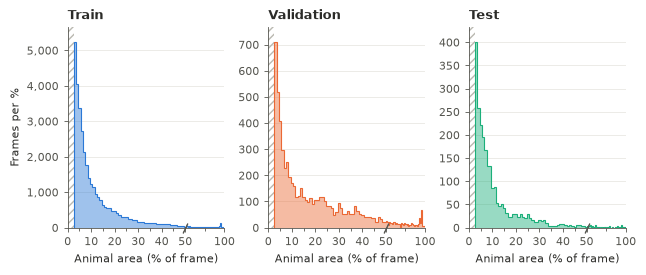

In [44]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, FuncFormatter

src = "display/animal_size/frames_area.csv"
d = pd.read_csv(src)
a = d[d.label == 1].copy()
a["pct"] = a["area"] * 100

mpl.rcParams.update({
    "font.family": "Inter", "font.size": 8, "axes.linewidth": 0.6,
    "axes.edgecolor": "#55554f", "axes.labelcolor": "#2b2b28",
    "xtick.color": "#55554f", "ytick.color": "#55554f",
    "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.major.size": 3, "ytick.major.size": 3,
    "pdf.fonttype": 42, "svg.fonttype": "none",
})
INK, GRID = "#2b2b28", "#e4e3dd"
COL = {"train": "#2a78d6", "val": "#eb6834", "test": "#1baf7a"}
NAME = {"train": "Train", "val": "Validation", "test": "Test"}
BW = 1.0  # histogram bin width in percentage points
bins = np.r_[np.arange(2.5, 100, BW), 100]

# piecewise-linear x-axis: 0–50% fills 75% of the width, 50–100% the last 25%
BREAK, SPLIT = 50.0, 75.0
def fwd(x):
    x = np.asarray(x, float)
    return np.where(x <= BREAK, x * SPLIT / BREAK,
                    SPLIT + (x - BREAK) * (100 - SPLIT) / (100 - BREAK))
def inv(y):
    y = np.asarray(y, float)
    return np.where(y <= SPLIT, y * BREAK / SPLIT,
                    BREAK + (y - SPLIT) * (100 - BREAK) / (100 - SPLIT))

fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.6))  # double-column width
fig.subplots_adjust(wspace=0.28)

for i, (ax, s) in enumerate(zip(axes, ["train", "val", "test"])):
    x = a.loc[a.split == s, "pct"].values
    c = COL[s]
    h, _ = np.histogram(x, bins=bins)

    ax.set_xscale("function", functions=(fwd, inv))

    # excluded region (<2.5%)
    ax.axvspan(0, 2.5, fc="none", hatch="////", ec="#b9b8b0", lw=0)

    # histogram only (1-pt bins): filled bars + crisp outline
    ax.bar(bins[:-1], h, width=BW, align="edge", color=c, alpha=0.45,
           lw=0, zorder=2)
    ax.stairs(h, bins, color=c, lw=0.8, zorder=3)

    ax.set_xlim(0, 100)
    ax.set_ylim(0, h.max() * 1.08)
    ax.xaxis.set_major_locator(FixedLocator([0, 10, 20, 30, 40, 50, 100]))
    ax.xaxis.set_minor_locator(FixedLocator(list(range(5, 50, 10)) + [75]))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}"))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.grid(axis="y", color=GRID, lw=0.5)
    ax.set_axisbelow(True)
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)

    # small break mark on the x-axis at 50% to flag the scale change
    ax.plot([50, 50], [0, 0], transform=ax.get_xaxis_transform(),
            marker=[(-1.2, -2.5), (1.2, 2.5)], ms=7, mew=0.8,
            color="#55554f", clip_on=False, zorder=6)

    ax.set_xlabel("Animal area (% of frame)")
    if i == 0:
        ax.set_ylabel("Frames per %")
    ax.set_title(NAME[s], loc="left", fontsize=9,
                 color=INK, fontweight="semibold", pad=6)

fig.savefig("display/animal_area_distribution.svg", bbox_inches="tight")
print("ok")

In [25]:
import numpy as np, pandas as pd
from pathlib import Path
from safari_vww import SaFariVWW

rows = []
for run in ("scratch96_s0", "ft96_s0", "ft128_s0"):
    d = Path("../logs") / run / "val_preds"
    y = np.load(d / "labels.npy")
    bal = np.array([SaFariVWW._binary_metrics(y, np.load(f), 0.5)["balanced_accuracy"]
                    for f in sorted(d.glob("ep*.npy"))])
    b = int(np.argmax(bal))                                   # first maximum = earliest epoch
    rows.append({"run": run.replace("_s0", ""), "best_epoch": b + 1,
                 "val_bal_best": round(bal[b], 4), "val_bal_last": round(bal[-1], 4),
                 "last_minus_best": round(bal[-1] - bal[b], 4)})
print(pd.DataFrame(rows).to_string(index=False))

      run  best_epoch  val_bal_best  val_bal_last  last_minus_best
scratch96          11        0.6883        0.5966          -0.0917
     ft96          13        0.7579        0.7143          -0.0437
    ft128          12        0.7881        0.7365          -0.0516


 Modelo  Melhor época cv_bacc melhor / 50 cv_loss melhor / 50  Época de menor cv_loss loss treino melhor / 50
 96×96s            11     0.6883 / 0.5966     0.7039 / 1.0013                       4         0.5263 / 0.3343
  96×96            13     0.7579 / 0.7143     0.6104 / 0.7097                       1         0.3755 / 0.2671
128×128            12     0.7881 / 0.7365     0.5093 / 0.7045                      11         0.3502 / 0.2346
saved /home/kitcovid-0738/safari/code/display/training_curves/training_curves.svg


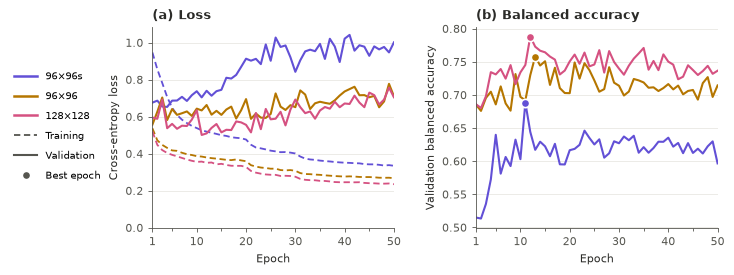

In [26]:
import os
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import FixedLocator, MultipleLocator
from matplotlib import font_manager

LOGS = os.path.expanduser("~/safari/logs")
MODELS = {"scratch96": "scratch96_s0", "ft96": "ft96_s0", "ft128": "ft128_s0"}
# one fixed colour per model — reuse these in every later figure of the paper
COL = {"scratch96": "#6250d6", "ft96": "#b57600", "ft128": "#d55181"}
# display names, as in Table 1 of the paper (internal keys stay the same)
LBL = {"scratch96": "96×96s", "ft96": "96×96", "ft128": "128×128"}
EXPECTED_BEST = {"scratch96": 11, "ft96": 13, "ft128": 12}
OUT_DIR = os.path.expanduser("~/safari/code/display/training_curves")   # <-
os.makedirs(OUT_DIR, exist_ok=True)                                     # <-
OUT = os.path.join(OUT_DIR, "training_curves.svg")                      # <-

# use Inter if installed, otherwise fall back silently (no findfont warnings)
_installed = {f.name for f in font_manager.fontManager.ttflist}
FONT = "Inter" if "Inter" in _installed else "DejaVu Sans"

mpl.rcParams.update({
    "font.family": FONT, "font.size": 8, "axes.linewidth": 0.6,
    "axes.edgecolor": "#55554f", "axes.labelcolor": "#2b2b28",
    "xtick.color": "#55554f", "ytick.color": "#55554f",
    "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.major.size": 3, "ytick.major.size": 3,
    "pdf.fonttype": 42, "svg.fonttype": "none",
})
INK, GRID, NEUTRAL = "#2b2b28", "#e4e3dd", "#55554f"

# ---------- data ----------
logs = {}
for name, folder in MODELS.items():
    df = pd.read_csv(os.path.join(LOGS, folder, "epochs.csv"))
    logs[name] = df[["global_epoch", "loss", "cv_loss",
                     "cv_balanced_accuracy"]].sort_values("global_epoch")

rows = []
for name, df in logs.items():
    e = df["global_epoch"].to_numpy()
    bacc = df["cv_balanced_accuracy"].to_numpy()
    ib = int(np.argmax(bacc))              # first maximum
    best = int(e[ib])
    assert best == EXPECTED_BEST[name], f"{name}: best epoch {best}, expected {EXPECTED_BEST[name]}"
    last = df[df.global_epoch == 50].iloc[0]
    at_best = df.iloc[ib]
    min_cv_ep = int(df.loc[df.cv_loss.idxmin(), "global_epoch"])
    rows.append({
        "Modelo": LBL[name],
        "Melhor época": best,
        "cv_bacc melhor / 50": f"{at_best.cv_balanced_accuracy:.4f} / {last.cv_balanced_accuracy:.4f}",
        "cv_loss melhor / 50": f"{at_best.cv_loss:.4f} / {last.cv_loss:.4f}",
        "Época de menor cv_loss": min_cv_ep,
        "loss treino melhor / 50": f"{at_best.loss:.4f} / {last.loss:.4f}",
    })
table = pd.DataFrame(rows)
print(table.to_string(index=False))                                          # <-
table.to_csv(os.path.join(OUT_DIR, "training_curves_table.csv"), index=False)  # <-

# ---------- figure ----------
fig, (axA, axB) = plt.subplots(1, 2, figsize=(7.2, 2.6), sharex=True)
fig.subplots_adjust(left=0.205, right=0.99, wspace=0.34)

for name, df in logs.items():
    c = COL[name]
    axA.plot(df.global_epoch, df.loss, color=c, lw=1.3, ls=(0, (3.5, 2)))
    axA.plot(df.global_epoch, df.cv_loss, color=c, lw=1.5)

    axB.plot(df.global_epoch, df.cv_balanced_accuracy, color=c, lw=1.5)
    ib = int(np.argmax(df.cv_balanced_accuracy.to_numpy()))
    axB.plot(df.global_epoch.iloc[ib], df.cv_balanced_accuracy.iloc[ib], "o",
             ms=6, mfc=c, mec="white", mew=1.2, zorder=5)

for ax, ylab, title in ((axA, "Cross-entropy loss", "(a) Loss"),
                        (axB, "Validation balanced accuracy", "(b) Balanced accuracy")):
    ax.set_xlim(1, 50)
    ax.xaxis.set_major_locator(FixedLocator([1, 10, 20, 30, 40, 50]))
    ax.xaxis.set_minor_locator(MultipleLocator(5))
    ax.grid(axis="y", color=GRID, lw=0.5)
    ax.set_axisbelow(True)
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylab)
    ax.set_title(title, loc="left", fontsize=9, color=INK,
                 fontweight="semibold", pad=6)
axA.set_ylim(bottom=0)

# legend: colour = model, line style = split
handles = [Line2D([], [], color=COL[m], lw=1.8, label=LBL[m]) for m in MODELS]
handles += [Line2D([], [], color=NEUTRAL, lw=1.3, ls=(0, (3.5, 2)), label="Training"),
            Line2D([], [], color=NEUTRAL, lw=1.5, label="Validation"),
            Line2D([], [], ls="none", marker="o", ms=6, mfc=NEUTRAL, mec="white",
                   mew=1.2, label="Best epoch")]
fig.legend(handles=handles, loc="center left", ncol=1, frameon=False,
           bbox_to_anchor=(0.0, 0.5), handlelength=2.2, labelspacing=0.9,
           fontsize=7.5)

fig.savefig(OUT, bbox_inches="tight")
print("saved", OUT)

           rule     run  bal_acc   AUC  precision  recall
     Best epoch  96x96s    0.641 0.696      0.633   0.590
     Best epoch   96x96    0.711 0.791      0.694   0.701
     Best epoch 128x128    0.724 0.815      0.781   0.601
Last epoch (50)  96x96s    0.663 0.723      0.625   0.710
Last epoch (50)   96x96    0.720 0.798      0.691   0.739
Last epoch (50) 128x128    0.768 0.856      0.771   0.732 

saved /home/kitcovid-0738/safari/code/display/test_results/test_confusion_matrices.svg


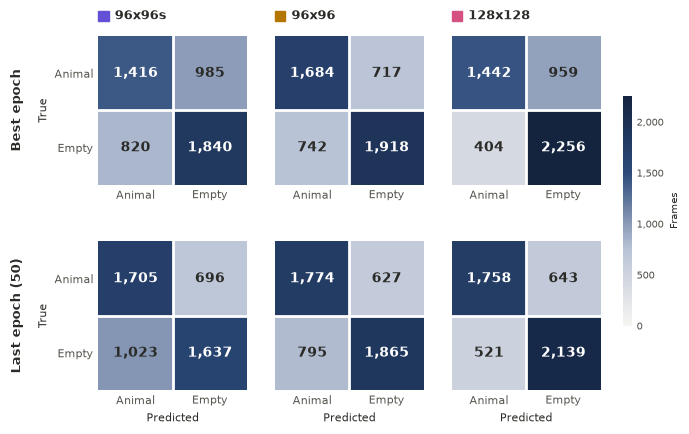

In [34]:
import os
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle
from pathlib import Path
from safari_vww import SaFariVWW

# ---------------- config ----------------
LOGS = Path("../logs")
OUT_DIR = Path(os.path.expanduser("~/safari/code/display/test_results"))
OUT_DIR.mkdir(parents=True, exist_ok=True)
RUNS = ("scratch96_s0", "ft96_s0", "ft128_s0")
RULES = ("best", "last")
RULE_LBL = {"best": "Best epoch", "last": "Last epoch (50)"}
COL = {"scratch96": "#6250d6", "ft96": "#b57600", "ft128": "#d55181"}
LBL = {"scratch96": "96x96s", "ft96": "96x96", "ft128": "128x128"}   # display names
THR = 0.5
DEC = 3

FONT = "Inter" if "Inter" in {f.name for f in font_manager.fontManager.ttflist} else "DejaVu Sans"
mpl.rcParams.update({
    "font.family": FONT, "font.size": 8,
    "axes.labelcolor": "#2b2b28", "xtick.color": "#55554f", "ytick.color": "#55554f",
    "pdf.fonttype": 42, "svg.fonttype": "none",
})
INK = "#2b2b28"

# ---------------- metrics ----------------
MODELS = [r.replace("_s0", "") for r in RUNS]
rows = []
for rule in RULES:
    for run in MODELS:
        d = pd.read_csv(LOGS / f"{run}_s0" / f"diag_{rule}_test_frames.csv")
        assert ((d.prob_animal >= THR).astype(int) == d.pred).all(), f"{run}/{rule}: pred != prob>=thr"
        m = SaFariVWW._binary_metrics(d.label.values, d.prob_animal.values, THR)
        rows.append({"rule": rule, "run": run,
                     "TP": m["tp"], "FN": m["fn"], "FP": m["fp"], "TN": m["tn"],
                     "bal_acc": m["balanced_accuracy"], "AUC": m["auc"],
                     "precision": m["precision_animal"], "recall": m["recall_animal"]})
R = pd.DataFrame(rows)

# ---------------- metrics table (plain print) ----------------
T = R[["rule", "run", "bal_acc", "AUC", "precision", "recall"]].copy()
T["rule"] = T["rule"].map(RULE_LBL)
T["run"] = T["run"].map(LBL)
print(T.round(DEC).to_string(index=False), "\n")

# ---------------- confusion matrices ----------------
CMAP = LinearSegmentedColormap.from_list("ink", ["#f6f5f1", "#b9c3d6", "#2c4a7a", "#14243f"])
CLS = ["Animal", "Empty"]
VMAX = int(R[["TP", "FN", "FP", "TN"]].to_numpy().max())   # one colour scale for all panels

fig, axes = plt.subplots(len(RULES), len(MODELS), figsize=(7.2, 4.6))
fig.subplots_adjust(left=0.17, right=0.88, wspace=0.12, hspace=0.38)

for ri, rule in enumerate(RULES):
    for ci, run in enumerate(MODELS):
        ax = axes[ri, ci]
        r = R[(R.rule == rule) & (R.run == run)].iloc[0]
        cnt = np.array([[r.TP, r.FN], [r.FP, r.TN]])       # rows = true, cols = predicted
        ax.imshow(cnt, cmap=CMAP, vmin=0, vmax=VMAX)
        for (i, j), v in np.ndenumerate(cnt):
            ax.text(j, i, f"{v:,}", ha="center", va="center", fontsize=10,
                    fontweight="semibold", color="white" if v > 0.55 * VMAX else INK)
        ax.axhline(0.5, color="white", lw=2)
        ax.axvline(0.5, color="white", lw=2)
        ax.set_xticks([0, 1], CLS)
        ax.set_yticks([0, 1], CLS if ci == 0 else ["", ""])
        ax.tick_params(length=0)
        ax.spines[:].set_visible(False)
        if ri == len(RULES) - 1:
            ax.set_xlabel("Predicted")
        if ci == 0:
            ax.set_ylabel("True")
            ax.text(-0.55, 0.5, RULE_LBL[rule], transform=ax.transAxes, rotation=90,
                    ha="center", va="center", fontsize=9, fontweight="semibold", color=INK)
        if ri == 0:
            ax.add_patch(Rectangle((0.0, 1.10), 0.07, 0.07, transform=ax.transAxes,
                                   color=COL[run], clip_on=False))
            ax.text(0.11, 1.135, LBL[run], transform=ax.transAxes, ha="left", va="center",
                    fontsize=9, fontweight="semibold", color=INK)

cax = fig.add_axes([0.905, 0.25, 0.012, 0.5])
cb = fig.colorbar(plt.cm.ScalarMappable(cmap=CMAP, norm=mpl.colors.Normalize(0, VMAX)), cax=cax)
cb.ax.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
cb.outline.set_visible(False)
cb.ax.tick_params(length=0, labelsize=7)
cb.set_label("Frames", fontsize=7.5, color=INK)

out = OUT_DIR / "test_confusion_matrices.svg"
fig.savefig(out, bbox_inches="tight")
print("saved", out)

In [46]:
import numpy as np, pandas as pd
from pathlib import Path
from safari_tools import SaFariAnnotation
from safari_vww import SaFariVWW

RUNS = {"96x96s": "scratch96_s0", "96x96": "ft96_s0", "128x128": "ft128_s0"}

def by_size(y, p, a):
    """Empty recall, then per size group: animal recall at 0.5 and AUC of that group against all empty frames."""
    e = p[y == 0]
    out = {"empty_rec": round(float((e < 0.5).mean()), 3)}
    for lo, hi, n in SaFariVWW.SIZE_BUCKETS:
        g = p[(y == 1) & (a > lo) & (a <= hi)]
        out[f"rec {n}"] = round(float((g >= 0.5).mean()), 3)
        out[f"AUC {n}"] = round(SaFariVWW._binary_metrics(np.r_[np.ones(len(g)), np.zeros(len(e))], np.r_[g, e])["auc"], 3)
    return out

# ---- A) test: best vs last epoch ----
rows = []
for m, run in RUNS.items():
    for rule in ("best", "last"):
        d = pd.read_csv(f"../logs/{run}/diag_{rule}_test_frames.csv")
        rows.append({"run": m, "rule": rule, **by_size(d.label.values, d.prob_animal.values, d.animal_frac.values)})
print("A) TEST: recall at 0.5 and threshold-free AUC per size group (group animals vs all empty frames)")
print(pd.DataFrame(rows).to_string(index=False), "\n")

# ---- B) validation: how the same quantities evolve over training ----
vww = SaFariVWW(SaFariAnnotation.from_json("../data/hf_sa_fari/annotation/sa_fari_train.json"))
V = list(vww._frame_fracs("../data/plans/split_val.csv"))
yv = np.array([l for _, l, _ in V]); av = np.array([f for _, _, f in V])
rows = []
for m, run in RUNS.items():
    d = Path(f"../logs/{run}")
    ok = (np.load(d / "val_preds/labels.npy") == yv).all() and \
         (pd.read_csv(d / "data/val.csv").path.values == np.array([p for p, _, _ in V])).all()
    E = pd.read_csv(d / "epochs.csv")
    best = int(E.loc[E.cv_balanced_accuracy.idxmax(), "global_epoch"])
    for ep in sorted({1, 5, best, 20, 30, 40, 50}):
        p = np.load(d / f"val_preds/ep{ep:03d}.npy")
        rows.append({"run": m, "epoch": ep, "best": "<-" if ep == best else "", "order_ok": ok, **by_size(yv, p, av)})
print("B) VALIDATION over epochs (same quantities)")
print(pd.DataFrame(rows).to_string(index=False))

A) TEST: recall at 0.5 and threshold-free AUC per size group (group animals vs all empty frames)
    run rule  empty_rec  rec 2.5-5%  AUC 2.5-5%  rec 5-10%  AUC 5-10%  rec 10-20%  AUC 10-20%  rec >=20%  AUC >=20%
 96x96s best      0.692       0.464       0.618      0.559      0.671       0.658       0.736      0.816      0.850
 96x96s last      0.615       0.619       0.653      0.681      0.697       0.774       0.772      0.871      0.855
  96x96 best      0.721       0.542       0.682      0.679      0.781       0.839       0.877      0.901      0.923
  96x96 last      0.701       0.592       0.699      0.714      0.790       0.859       0.872      0.938      0.922
128x128 best      0.848       0.437       0.729      0.575      0.818       0.705       0.858      0.851      0.926
128x128 last      0.804       0.568       0.772      0.728      0.860       0.870       0.914      0.906      0.945 

B) VALIDATION over epochs (same quantities)
    run  epoch best  order_ok  empty_rec  rec

In [38]:
import numpy as np, pandas as pd
from pathlib import Path
from safari_vww import SaFariVWW

LOGS, THR, B, SEED = Path("../logs"), 0.5, 10_000, 0
RUNS = {"96x96s": "scratch96_s0", "96x96": "ft96_s0", "128x128": "ft128_s0"}
RULES = ("best", "last")
METRICS = ("bal_acc", "AUC", "precision", "recall")

# ---- data: 6 prediction files, same frames, labels and cameras ----
P = {(m, r): pd.read_csv(LOGS / run / f"diag_{r}_test_frames.csv") for m, run in RUNS.items() for r in RULES}
ref = P[("96x96s", "last")]
same = all((d.path.values == ref.path.values).all() and (d.label.values == ref.label.values).all()
           and (d.camera.values == ref.camera.values).all() for d in P.values())
y = ref.label.values.astype(int)
cam, cams = pd.factorize(ref.camera)          # camera index per frame (order of first appearance)
C = len(cams)

# ---- camera draws: one set, shared by all models and rules ----
rng = np.random.default_rng(SEED)
W = np.stack([np.bincount(rng.integers(0, C, C), minlength=C) for _ in range(B)])   # (B, C) times each camera drawn
frames_per_draw = W @ np.bincount(cam, minlength=C)

def from_counts(tp, fn, fp, tn):
    with np.errstate(divide="ignore", invalid="ignore"):
        ra, re = tp / (tp + fn), tn / (tn + fp)
        return {"bal_acc": (ra + re) / 2, "precision": tp / (tp + fp), "recall": ra}

def make_auc(p):
    """AUC with frame weights; tied scores count 1/2 (same as rank-based AUC with average ranks)."""
    vals, inv = np.unique(p, return_inverse=True)
    G = len(vals)
    def auc(w):
        pos, neg = np.bincount(inv, w * y, G), np.bincount(inv, w * (1 - y), G)
        below = np.cumsum(neg) - neg
        return (pos * (below + 0.5 * neg)).sum() / (pos.sum() * neg.sum())
    return auc

# ---- point estimates + bootstrap ----
est, boot, match = {}, {}, True
for key, d in P.items():
    p = d.prob_animal.values
    pred = (p >= THR).astype(int)
    cells = [(pred == 1) & (y == 1), (pred == 0) & (y == 1), (pred == 1) & (y == 0), (pred == 0) & (y == 0)]
    cnt = np.stack([np.bincount(cam, c.astype(float), C) for c in cells], axis=1)   # (C, 4): TP FN FP TN per camera
    auc = make_auc(p)
    e = from_counts(*cnt.sum(0)); e["AUC"] = auc(np.ones(len(y)))
    m = SaFariVWW._binary_metrics(y, p, THR)
    match &= all(np.isclose(e[k], m[j]) for k, j in
                 [("bal_acc", "balanced_accuracy"), ("AUC", "auc"), ("precision", "precision_animal"), ("recall", "recall_animal")])
    b = from_counts(*(W @ cnt).T); b["AUC"] = np.array([auc(W[i][cam].astype(float)) for i in range(B)])
    est[key], boot[key] = e, b

# ---- checks ----
print(f"same frames, labels and cameras in all 6 files: {same}")
print(f"cameras: {C} | resamples: {B:,} | seed: {SEED} | draw fingerprint: {int((W * np.arange(C)).sum())}")
print(f"frames per resample: min {frames_per_draw.min():,} | median {int(np.median(frames_per_draw)):,} | max {frames_per_draw.max():,}")
print(f"point estimates equal SaFariVWW._binary_metrics: {match}")
print("undefined resamples (nan) per metric:",
      {k: int(sum(np.isnan(boot[key][k]).sum() for key in P)) for k in METRICS}, "\n")

ci = lambda x: np.nanpercentile(x, [2.5, 97.5])
def show(e, x, sign=""):
    lo, hi = ci(x)
    return f"{e:{sign}.3f} [{lo:{sign}.3f}, {hi:{sign}.3f}]"

# T1: metrics with 95% CI
print("T1  metrics, 95% camera-bootstrap CI")
print(pd.DataFrame([{"rule": r, "run": m, **{k: show(est[(m, r)][k], boot[(m, r)][k]) for k in METRICS}}
                    for r in RULES for m in RUNS]).to_string(index=False), "\n")

# T2: differences between models, within each rule
PAIRS = [("96x96", "96x96s"), ("128x128", "96x96"), ("128x128", "96x96s")]
print("T2  differences between models (a - b), same rule")
print(pd.DataFrame([{"rule": r, "a - b": f"{a} - {b}",
                     **{k: show(est[(a, r)][k] - est[(b, r)][k], boot[(a, r)][k] - boot[(b, r)][k], "+") for k in METRICS}}
                    for r in RULES for a, b in PAIRS]).to_string(index=False), "\n")

# T3: differences between rules, within each model
print("T3  differences between rules (last - best), same model")
print(pd.DataFrame([{"run": m, **{k: show(est[(m, "last")][k] - est[(m, "best")][k],
                                          boot[(m, "last")][k] - boot[(m, "best")][k], "+") for k in METRICS}}
                    for m in RUNS]).to_string(index=False))

same frames, labels and cameras in all 6 files: True
cameras: 91 | resamples: 10,000 | seed: 0 | draw fingerprint: 40969725
frames per resample: min 2,920 | median 5,060 | max 7,233
point estimates equal SaFariVWW._binary_metrics: True
undefined resamples (nan) per metric: {'bal_acc': 0, 'AUC': 0, 'precision': 0, 'recall': 0} 

T1  metrics, 95% camera-bootstrap CI
rule     run              bal_acc                  AUC            precision               recall
best  96x96s 0.641 [0.599, 0.677] 0.696 [0.654, 0.734] 0.633 [0.557, 0.704] 0.590 [0.515, 0.661]
best   96x96 0.711 [0.667, 0.754] 0.791 [0.743, 0.832] 0.694 [0.619, 0.765] 0.701 [0.639, 0.760]
best 128x128 0.724 [0.684, 0.761] 0.815 [0.772, 0.852] 0.781 [0.713, 0.840] 0.601 [0.530, 0.668]
last  96x96s 0.663 [0.613, 0.706] 0.723 [0.671, 0.770] 0.625 [0.557, 0.687] 0.710 [0.647, 0.768]
last   96x96 0.720 [0.683, 0.754] 0.798 [0.756, 0.835] 0.691 [0.632, 0.745] 0.739 [0.679, 0.793]
last 128x128 0.768 [0.731, 0.802] 0.856 [0.818, 0.8

In [39]:
# ---- 3.3.6: animal recall by size group (T4) and model differences (T5) ----
import numpy as np, pandas as pd
from pathlib import Path
from safari_vww import SaFariVWW

LOGS, THR, B, SEED = Path("../logs"), 0.5, 10_000, 0
RUNS = {"96x96s": "scratch96_s0", "96x96": "ft96_s0", "128x128": "ft128_s0"}
RULES = ("best", "last")
PAIRS = [("96x96", "96x96s"), ("128x128", "96x96"), ("128x128", "96x96s")]

# ---- data and camera draws: identical construction to 3.3.5 ----
P = {(m, r): pd.read_csv(LOGS / run / f"diag_{r}_test_frames.csv") for m, run in RUNS.items() for r in RULES}
ref = P[("96x96s", "last")]
y = ref.label.values.astype(int)
cam, cams = pd.factorize(ref.camera)
C = len(cams)
rng = np.random.default_rng(SEED)
W = np.stack([np.bincount(rng.integers(0, C, C), minlength=C) for _ in range(B)])
print(f"draw fingerprint: {int((W * np.arange(C)).sum())}  (3.3.5: 40969725)")

# ---- size groups: (lo, hi] from SaFariVWW.SIZE_BUCKETS, animal frames only ----
a = ref.animal_frac.values
same = all((d.path.values == ref.path.values).all() and np.allclose(d.animal_frac.values, a) for d in P.values())
print(f"same frames and animal areas in all 6 files: {same}")
GROUPS = [(n, (y == 1) & (a > lo) & (a <= hi)) for lo, hi, n in SaFariVWW.SIZE_BUCKETS]
print("animal frames per group:", {n: int(g.sum()) for n, g in GROUPS},
      f"| total {sum(int(g.sum()) for _, g in GROUPS):,} of {int(y.sum()):,}")
print("cameras per group:", {n: int(np.unique(cam[g]).size) for n, g in GROUPS}, "\n")

# ---- recall per group: point estimate + bootstrap ----
rows, boot, nan_count = [], {}, 0
for (m, r), d in P.items():
    hit = (d.prob_animal.values >= THR) & (y == 1)
    for n, g in GROUPS:
        h_c = np.bincount(cam, (hit & g).astype(float), C)
        n_c = np.bincount(cam, g.astype(float), C)
        with np.errstate(invalid="ignore", divide="ignore"):
            bt = (W @ h_c) / (W @ n_c)
        nan_count += int(np.isnan(bt).sum())
        boot[(m, r, n)] = bt
        lo, hi = np.nanpercentile(bt, [2.5, 97.5])
        rows.append({"rule": r, "run": m, "size_group": n, "found": int(h_c.sum()), "n": int(n_c.sum()),
                     "recall": round(h_c.sum() / n_c.sum(), 4), "ci_low": round(lo, 4), "ci_high": round(hi, 4)})
R = pd.DataFrame(rows)
print(f"undefined resamples (no frames of a group drawn): {nan_count}\n")

tot = R.groupby(["rule", "run"])[["found", "n"]].sum()
print("overall recall from groups (must equal 3.3.4):")
print((tot.found / tot.n).round(4).unstack().to_string(), "\n")

print("T4  animal recall by size group, 95% camera-bootstrap CI")
print(R.to_string(index=False), "\n")

D = []
for r in RULES:
    for x, z in PAIRS:
        for n, _ in GROUPS:
            e = R.query("rule == @r and run == @x and size_group == @n").recall.item() - \
                R.query("rule == @r and run == @z and size_group == @n").recall.item()
            lo, hi = np.nanpercentile(boot[(x, r, n)] - boot[(z, r, n)], [2.5, 97.5])
            D.append({"rule": r, "a - b": f"{x} - {z}", "size_group": n,
                      "diff": round(e, 4), "ci_low": round(lo, 4), "ci_high": round(hi, 4)})
print("T5  recall differences between models (a - b), same rule and group")
print(pd.DataFrame(D).to_string(index=False))

T4 = R.copy()   # own name, so later cells can't overwrite it

draw fingerprint: 40969725  (3.3.5: 40969725)
same frames and animal areas in all 6 files: True
animal frames per group: {'2.5-5%': 782, '5-10%': 769, '10-20%': 447, '>=20%': 403} | total 2,401 of 2,401
cameras per group: {'2.5-5%': 70, '5-10%': 68, '10-20%': 56, '>=20%': 39} 

undefined resamples (no frames of a group drawn): 0

overall recall from groups (must equal 3.3.4):
run   128x128   96x96  96x96s
rule                         
best   0.6006  0.7014  0.5898
last   0.7322  0.7389  0.7101 

T4  animal recall by size group, 95% camera-bootstrap CI
rule     run size_group  found   n  recall  ci_low  ci_high
best  96x96s     2.5-5%    363 782  0.4642  0.3656   0.5642
best  96x96s      5-10%    430 769  0.5592  0.4572   0.6597
best  96x96s     10-20%    294 447  0.6577  0.5450   0.7601
best  96x96s      >=20%    329 403  0.8164  0.7377   0.8889
last  96x96s     2.5-5%    484 782  0.6189  0.5326   0.7028
last  96x96s      5-10%    524 769  0.6814  0.5866   0.7654
last  96x96s     10-20

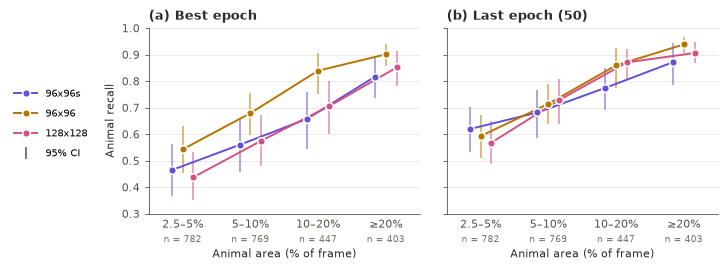

saved /home/kitcovid-0738/safari/code/display/recall_by_size/recall_by_size.svg

(a) Best epoch: recall [95% CI]  found/n
run                                   96x96s                             96x96                           128x128
size group                                                                                                      
2.5–5%      0.4642 [0.3656, 0.5642]  363/782  0.5422 [0.4545, 0.6298]  424/782  0.4373 [0.3512, 0.5310]  342/782
5–10%       0.5592 [0.4572, 0.6597]  430/769  0.6788 [0.5974, 0.7554]  522/769  0.5748 [0.4794, 0.6711]  442/769
10–20%      0.6577 [0.5450, 0.7601]  294/447  0.8389 [0.7516, 0.9047]  375/447  0.7047 [0.6021, 0.8000]  315/447
≥20%        0.8164 [0.7377, 0.8889]  329/403  0.9007 [0.8551, 0.9393]  363/403  0.8511 [0.7827, 0.9115]  343/403

(b) Last epoch (50): recall [95% CI]  found/n
run                                   96x96s                             96x96                           128x128
size group                              

In [40]:
# ---- Fig. 4.3: animal recall by size group (uses R = T4 from the 3.3.6 cell) ----
import os
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.lines import Line2D
from pathlib import Path

OUT = Path(os.path.expanduser("~/safari/code/display/recall_by_size")) / "recall_by_size.svg"
OUT.parent.mkdir(parents=True, exist_ok=True)

MODELS = ["96x96s", "96x96", "128x128"]                       # same order as the other figures
COL = {"96x96s": "#6250d6", "96x96": "#b57600", "128x128": "#d55181"}
RULES = [("best", "(a) Best epoch"), ("last", "(b) Last epoch (50)")]
GROUPS = ["2.5-5%", "5-10%", "10-20%", ">=20%"]                 # keys as printed in T4
GLBL = {"2.5-5%": "2.5–5%", "5-10%": "5–10%", "10-20%": "10–20%", ">=20%": "≥20%"}
DODGE = {"96x96s": -0.16, "96x96": 0.0, "128x128": 0.16}       # keeps the CIs from overlapping

FONT = "Inter" if "Inter" in {f.name for f in font_manager.fontManager.ttflist} else "DejaVu Sans"
mpl.rcParams.update({
    "font.family": FONT, "font.size": 8, "axes.linewidth": 0.6,
    "axes.edgecolor": "#55554f", "axes.labelcolor": "#2b2b28",
    "xtick.color": "#55554f", "ytick.color": "#55554f",
    "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.major.size": 3, "ytick.major.size": 3,
    "pdf.fonttype": 42, "svg.fonttype": "none",
})
INK, MUTED, GRID, NEUTRAL = "#2b2b28", "#6f6e66", "#e4e3dd", "#55554f"

# sanity: T4 has every rule x model x group exactly once, and n is the same across models
assert len(R) == len(RULES) * len(MODELS) * len(GROUPS)
N = R.groupby("size_group")["n"].agg(["min", "max"])
assert (N["min"] == N["max"]).all(), "n per group differs between models"
NG = N["min"].to_dict()

fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.9), sharey=True)
fig.subplots_adjust(left=0.20, right=0.99, wspace=0.10, bottom=0.24)
x = np.arange(len(GROUPS))

for ax, (rule, title) in zip(axes, RULES):
    for m in MODELS:
        d = R[(R.rule == rule) & (R.run == m)].set_index("size_group").loc[GROUPS]
        xs = x + DODGE[m]
        ax.vlines(xs, d.ci_low, d.ci_high, color=COL[m], lw=1.2, alpha=0.6, zorder=2)
        ax.plot(xs, d.recall, color=COL[m], lw=1.4, zorder=3)
        ax.plot(xs, d.recall, "o", ms=5.5, mfc=COL[m], mec="white", mew=1.1, zorder=4)

    ax.set_xlim(-0.5, len(GROUPS) - 0.5)
    ax.set_ylim(0.3, 1.0)
    ax.set_xticks(x, [GLBL[g] for g in GROUPS])
    ax.tick_params(axis="x", length=0, pad=4)
    # frames per group under each tick
    for xi, g in zip(x, GROUPS):
        ax.text(xi, -0.115, f"n = {NG[g]:,}", transform=ax.get_xaxis_transform(),
                ha="center", va="top", fontsize=6.8, color=MUTED)
    ax.grid(axis="y", color=GRID, lw=0.5)
    ax.set_axisbelow(True)
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)
    ax.set_xlabel("Animal area (% of frame)", labelpad=13)
    ax.set_title(title, loc="left", fontsize=9, color=INK, fontweight="semibold", pad=6)
axes[0].set_ylabel("Animal recall")

handles = [Line2D([], [], color=COL[m], lw=1.4, marker="o", ms=5.5, mfc=COL[m],
                  mec="white", mew=1.1, label=m) for m in MODELS]
handles += [Line2D([], [], color=NEUTRAL, lw=1.1, marker="|", ms=9, mew=1.1, ls="none",
                   label="95% CI")]
fig.legend(handles=handles, loc="center left", ncol=1, frameon=False,
           bbox_to_anchor=(0.0, 0.55), handlelength=2.2, labelspacing=0.9, fontsize=7.5)

fig.savefig(OUT, bbox_inches="tight")
plt.show()
print("saved", OUT)

# ---- exact numbers plotted: recall [95% CI] and found/n, per rule ----
for rule, title in RULES:
    t = R[R.rule == rule].copy()
    t["value"] = t.apply(lambda r: f"{r.recall:.4f} [{r.ci_low:.4f}, {r.ci_high:.4f}]  {r.found}/{r.n}", axis=1)
    w = t.pivot(index="size_group", columns="run", values="value").loc[GROUPS, MODELS]
    w.index = [GLBL[g] for g in GROUPS]
    w.index.name = "size group"
    print(f"\n{title}: recall [95% CI]  found/n")
    print(w.to_string())

In [41]:
import os
os.environ.setdefault("TF_USE_LEGACY_KERAS", "1")
import numpy as np, pandas as pd, tensorflow as tf
from pathlib import Path
from PIL import Image
from safari_vww import SaFariVWW

RUNS = {"s96x96": ("scratch96_s0", 96), "96x96": ("ft96_s0", 96), "128x128": ("ft128_s0", 128)}

def img(root, p):
    return np.asarray(Image.open(Path(root) / p).convert("RGB"), np.float32) / 255.0

def macs(model):
    t = 0
    for l in model.layers:
        if isinstance(l, tf.keras.layers.DepthwiseConv2D):
            _, h, w, c = l.output_shape; t += h * w * c * l.kernel_size[0] * l.kernel_size[1]
        elif isinstance(l, tf.keras.layers.Conv2D):
            _, h, w, c = l.output_shape; t += h * w * c * l.kernel_size[0] * l.kernel_size[1] * l.input_shape[-1]
        elif isinstance(l, tf.keras.layers.Dense):
            t += l.input_shape[-1] * l.units
    return t

def run_tflite(path, S, paths):
    """P(animal) for each test frame; int8 input/output are (de)quantized with the model's scale and zero point."""
    it = tf.lite.Interpreter(model_path=str(path)); it.allocate_tensors()
    i, o = it.get_input_details()[0], it.get_output_details()[0]
    (si, zi), (so, zo) = i["quantization"], o["quantization"]
    out = np.empty(len(paths), np.float32)
    for k, p in enumerate(paths):
        x = img(f"../data/vww{S}/sa_fari_test", p)
        if i["dtype"] == np.int8:
            x = np.clip(np.round(x / si + zi), -128, 127).astype(np.int8)
        it.set_tensor(i["index"], x[None]); it.invoke()
        y = it.get_tensor(o["index"])[0, 1]
        out[k] = (y.astype(np.float32) - zo) * so if o["dtype"] == np.int8 else y
    return out, i["dtype"].__name__, o["dtype"].__name__

rows = []
for name, (run, S) in RUNS.items():
    ck = Path(f"../checkpoints/{run}")
    model = tf.keras.models.load_model(ck / "last.h5", compile=False)
    d = pd.read_csv(f"../logs/{run}/diag_last_test_frames.csv")      # Keras results from training, same frames and order
    p32, i32, o32 = run_tflite(ck / "last_float32.tflite", S, d.path)
    p8, i8, o8 = run_tflite(ck / "last_int8.tflite", S, d.path)
    print(f"{name} | float32 tflite: in {i32}, out {o32}, max |P - Keras| {np.abs(p32 - d.prob_animal.values).max():.2e} "
          f"| int8 tflite: in {i8}, out {o8}, max |P - Keras| {np.abs(p8 - d.prob_animal.values).max():.3f}")

    for kind, prob, size in (("keras (diag)", d.prob_animal.values, (ck / "last.h5").stat().st_size),
                             ("tflite float32", p32, (ck / "last_float32.tflite").stat().st_size),
                             ("tflite int8", p8, (ck / "last_int8.tflite").stat().st_size)):
        m = SaFariVWW._binary_metrics(d.label.values, prob, 0.5)
        rows.append({"run": name, "input": S, "model": kind, "params": model.count_params(),
                     "MACs": macs(model), "bytes": size,
                     "bal_acc": round(m["balanced_accuracy"], 4), "AUC": round(m["auc"], 4),
                     "precision": round(m["precision_animal"], 4), "recall": round(m["recall_animal"], 4),
                     "TP": m["tp"], "FP": m["fp"]})

print(pd.DataFrame(rows).to_string(index=False))

/home/kitcovid-0738/safari/.venv/lib/python3.12/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


s96x96 | float32 tflite: in float32, out float32, max |P - Keras| 2.71e-03 | int8 tflite: in int8, out int8, max |P - Keras| 0.281
96x96 | float32 tflite: in float32, out float32, max |P - Keras| 2.47e-03 | int8 tflite: in int8, out int8, max |P - Keras| 0.348
128x128 | float32 tflite: in float32, out float32, max |P - Keras| 3.12e-03 | int8 tflite: in int8, out int8, max |P - Keras| 0.477
    run  input          model  params     MACs   bytes  bal_acc    AUC  precision  recall   TP   FP
 s96x96     96   keras (diag)  221794  7489664 1158840   0.6628 0.7233     0.6250  0.7101 1705 1023
 s96x96     96 tflite float32  221794  7489664  864724   0.6628 0.7233     0.6250  0.7101 1705 1023
 s96x96     96    tflite int8  221794  7489664  308504   0.6587 0.7189     0.6176  0.7197 1728 1070
  96x96     96   keras (diag)  221794  7489664 1158840   0.7200 0.7977     0.6905  0.7389 1774  795
  96x96     96 tflite float32  221794  7489664  864724   0.7200 0.7977     0.6905  0.7389 1774  795
  96x96

In [42]:
rows = []
for name, (run, S) in RUNS.items():
    ck = Path(f"../checkpoints/{run}")
    d = pd.read_csv(f"../logs/{run}/diag_last_test_frames.csv")
    pk, y = d.prob_animal.values, d.label.values
    for kind, f in (("tflite float32", "last_float32.tflite"), ("tflite int8", "last_int8.tflite")):
        p, _, _ = run_tflite(ck / f, S, d.path)
        changed = (p >= 0.5) != (pk >= 0.5)
        rows.append({"run": name, "model": kind,
                     "same_decision": f"{len(y) - changed.sum():,}/{len(y):,} ({1 - changed.mean():.4f})",
                     "changed_on_animal": int((changed & (y == 1)).sum()),
                     "changed_on_empty": int((changed & (y == 0)).sum()),
                     "mean_abs_dP": round(float(np.abs(p - pk).mean()), 4),
                     "max_abs_dP": round(float(np.abs(p - pk).max()), 4)})
print(pd.DataFrame(rows).to_string(index=False))

/home/kitcovid-0738/safari/.venv/lib/python3.12/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


    run          model        same_decision  changed_on_animal  changed_on_empty  mean_abs_dP  max_abs_dP
 s96x96 tflite float32 5,061/5,061 (1.0000)                  0                 0       0.0002      0.0027
 s96x96    tflite int8 4,925/5,061 (0.9731)                 37                99       0.0220      0.2806
  96x96 tflite float32 5,061/5,061 (1.0000)                  0                 0       0.0002      0.0025
  96x96    tflite int8 4,900/5,061 (0.9682)                 57               104       0.0248      0.3480
128x128 tflite float32 5,060/5,061 (0.9998)                  0                 1       0.0002      0.0031
128x128    tflite int8 4,916/5,061 (0.9713)                 65                80       0.0261      0.4767
